# ЛР 1. K ближайших соседей

## Данные

Avila. По 10 признакам фрагмента текста предсказываем одного из 12 переписчиков. Это помогает распределять фрагменты перед ручной проверкой. Используем разбиение UCI и три стратифицированных фолда в обучающей части. [Источник](https://doi.org/10.24432/C5K02X)

Tasmania. По координатам 16 преобразователей предсказываем мощность фермы. Это позволяет отбирать конфигурации перед запуском симулятора. Мощности отдельных преобразователей исключаем, поскольку их сумма практически равна цели. Берем 7200 конфигураций. Раскладки с одинаковыми координатами после округления до 10 м попадают в одну группу. Группы разделяем между обучением и тестом. В обучающей части три групповых фолда. [Источник](https://doi.org/10.24432/C5831S)

In [1]:
# Загрузка данных и проверка разбиений.
import pandas as pd
from IPython.display import display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 1
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila,20867,10430,10437,10,"Разбиение UCI, 3 стратифицированных фолда на t..."
1,Tasmania,72000,5762,1438,32,"20% групп на тесте, 3 групповых фолда на train."


,Avila
Точных совпадений векторов признаков между train/test,0


,Tasmania
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Метрики

Avila. Macro-F1 дает одинаковый вес каждому классу. Balanced accuracy усредняет полноту по классам. Accuracy показывает общую долю верных ответов.

Tasmania. MAE показывает средний промах в МВт. RMSE сильнее учитывает крупные ошибки. R² сравнивает модель с прогнозом среднего.

Для сравнения простая модель предсказывает самый частый класс или медианную мощность из обучающей выборки.

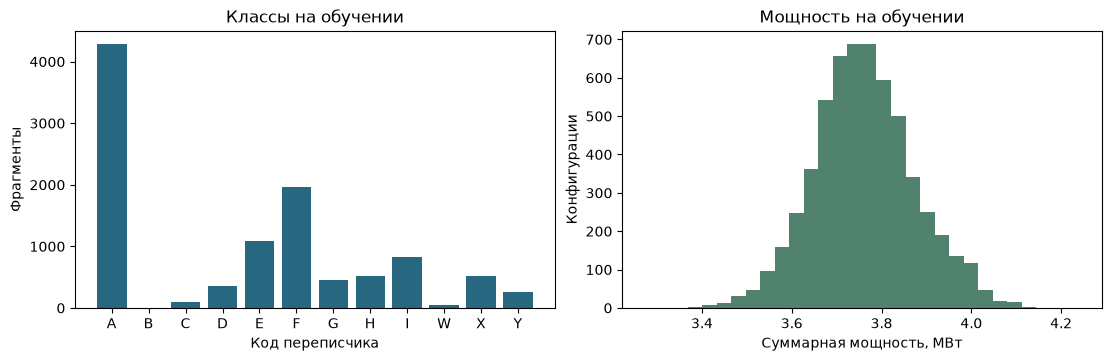

In [2]:
# Распределения классов и мощности на обучающей выборке.
plot_training(tasks)

## Бейзлайн sklearn

В обеих моделях sklearn берем 5 соседей, евклидово расстояние и равные веса. Классификатор голосует, регрессор берет среднее.

## Подбор параметров

В Avila проверяем обычное и робастное масштабирование, число соседей, веса и метрику расстояния. Масштабирование может уменьшить влияние признаков с большим разбросом. В Tasmania сравниваем координаты и геометрические признаки. Дополнительно проверяем усреднение по 11 соседям с весами по расстоянию.

Выбор по среднему macro-F1 или MAE на трех фолдах. Масштабирование обучается внутри каждого фолда. При равенстве оценок берем первый вариант.

In [3]:
# Проверка параметров на трех фолдах.
selections = select_candidates(LAB, tasks)
for task in tasks:
    print(f"{task.title} ({primary_metric(task)})")
    display(selections[task.key][2].round(5))

Avila (macro_f1)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.63366,0.02498,0.64778,0.60481,0.64837,False
1,Стандартизация,standard,{},0.61181,0.01015,0.61311,0.62125,0.60107,False
2,Робастное масштабирование,robust,{},0.82465,0.00993,0.81400,0.82630,0.83365,True
3,k=3 и взвешивание соседей,standard,"{""n_neighbors"": 3, ""weights"": ""distance""}",0.68910,0.02421,0.67751,0.71692,0.67286,False
4,Манхэттенское расстояние и k=11,standard,"{""n_neighbors"": 11, ""p"": 1}",0.57885,0.03049,0.55836,0.61389,0.56430,False


Tasmania (mae_mw)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.05892,0.00182,0.06100,0.05764,0.05813,False
1,Стандартизация координат,standard,{},0.05942,0.00158,0.06116,0.05808,0.05902,False
2,Геометрия со стандартизацией,geometry_standard,{},0.05341,0.00060,0.05334,0.05404,0.05285,False
3,"Геометрия, k=11 и взвешивание",geometry_standard,"{""n_neighbors"": 11, ""weights"": ""distance""}",0.05133,0.00041,0.05134,0.05174,0.05092,True
4,"Координаты, k=11 и взвешивание",raw,"{""n_neighbors"": 11, ""weights"": ""distance""}",0.05821,0.00130,0.05968,0.05722,0.05772,False


## Результаты sklearn

Начальную и выбранную модели обучаем на всей обучающей выборке и проверяем на тесте.

In [4]:
# Обучение моделей и замер метрик на тесте.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    print(task.title)
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,0.05840,1.93374,0.71828,0.66567,0.74954
2,sklearn tuned,Робастное масштабирование,0.08512,1.04769,0.88331,0.85999,0.86749


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.00623,0.16143,0.05975,0.07875,0.50802
2,sklearn tuned,"Геометрия, k=11 и взвешивание",0.55345,0.23673,0.05151,0.06929,0.61922


## Своя реализация

Считаем расстояния пакетами и выбираем k соседей частичной сортировкой. При весах по расстоянию точные совпадения получают все голоса. При равном расстоянии на границе k берем соседей в порядке строк train. При равных голосах берем первый класс в отсортированном списке.

Для обеих версий используем те же настройки и признаки, что у sklearn. [Код моделей](labkit/models.py)

In [5]:
# Метрики sklearn и собственных моделей.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    print(task.title)
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,0.05840,1.93374,0.71828,0.66567,0.74954
2,sklearn tuned,Робастное масштабирование,0.08512,1.04769,0.88331,0.85999,0.86749
3,own baseline,Бейзлайн,0.00801,5.68902,0.71828,0.66567,0.74954
4,own tuned,Робастное масштабирование,0.03273,6.83933,0.88331,0.85999,0.86749


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.00623,0.16143,0.05975,0.07875,0.50802
2,sklearn tuned,"Геометрия, k=11 и взвешивание",0.55345,0.23673,0.05151,0.06929,0.61922
3,own baseline,Бейзлайн,0.00286,0.79778,0.05975,0.07875,0.50802
4,own tuned,"Геометрия, k=11 и взвешивание",0.48195,0.69233,0.05151,0.06929,0.61922


## Ошибки на тесте

Графики для настроенных моделей sklearn. Строки матрицы ошибок показывают доли по истинному классу. Пунктир на графике мощности показывает идеальный прогноз.

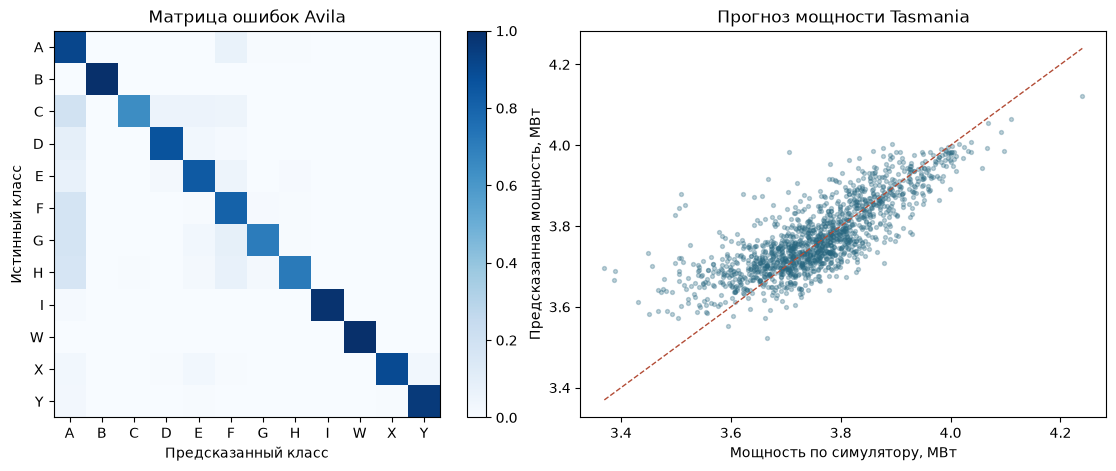

In [6]:
# Матрица ошибок и график прогноза мощности.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Выводы и запись метрик для итоговой таблицы.
print(comparison_text(tasks, results, selections))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

Avila (macro-F1)
По кросс-валидации выбран вариант «Робастное масштабирование».
Среднее на фолдах: 0.6337 до настройки и 0.8247 после.
Sklearn на тесте: 0.7183 до настройки и 0.8833 после.
Своя модель на тесте: 0.7183 до настройки и 0.8833 после.
Разница со sklearn на тесте: +0.0000 до настройки и +0.0000 после.

Tasmania (MAE, МВт)
По кросс-валидации выбран вариант «Геометрия, k=11 и взвешивание».
Среднее на фолдах: 0.0589 до настройки и 0.0513 после.
Sklearn на тесте: 0.0598 до настройки и 0.0515 после.
Своя модель на тесте: 0.0598 до настройки и 0.0515 после.
Разница со sklearn на тесте: +0.0000 до настройки и -0.0000 после.
Метрики сохранены в results/lab_01.csv
